In [1]:
import rawpy
import sys
import os
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio
import tifffile
import seaborn as sns
from pathlib import Path
import colour
# 1. Load the standard chart data
cc24_data = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
# 2. Convert the reference data from xyY color space to XYZ tristimulus values (t)
xyY_values = np.array(list(cc24_data.data.values()))

# 3. Convert the xyY array directly into CIE XYZ tristimulus values (t)
t_XYZ = colour.xyY_to_XYZ(list(xyY_values))

helperFolder = Path("helper")
if str(helperFolder.resolve()) not in sys.path:
    sys.path.insert(0, str(helperFolder.resolve()))

import utils
import psu_imaging as psu
importlib.reload(utils)
importlib.reload(psu)

# baseFilePath = 'images/IMG_0'
# startingImage = 278
# options = ['overhead','led','incandescent','outside1','outside2']
# imagePaths = dict((option, []) for option in options)
# for j in range(len(options)):
#     for i in range(0,4,1):
#         fileNumber = startingImage + i + j*4
#         imagePaths[options[j]].append(f"{baseFilePath}{fileNumber}.DNG")
print(cv2.__version__)

4.11.0


## Measurement 1: Intrinsics and Lens Distortion

Geometry: intrinsics and lens distortion. Calibrate with the printed checkerboard using cv2.calibrateCamera. Report focal length in pixels and in millimetres, principal point, the radial and tangential distortion coefficients, and the RMS reprojection error. Show an undistorted image next to the original with a straight edge in frame, so the correction is visible.

The comparison uses the first successfully detected checkerboard and its existing corner points. Cyan connects each corner row; yellow marks its orthogonal best-fit straight line. The straightness metric pools perpendicular residuals from all rows and columns; lower RMS means straighter grid lines. Corrected points use the same camera matrix and pixel scale as the remapped image. Mean/max corner displacement measures correction magnitude, not accuracy. This is an in-sample check using transformed corners, not redetection or independent validation. Rerun corner detection before the comparison to refresh the successful-image path list.

In [22]:
importlib.reload(utils) #reload utils file 

## Verify with lens_id that each file used the same camera

measurement1ImageFolder = Path("../../exercises/02_assignment/images")
measurement1ImagePaths = sorted(
    measurement1ImageFolder.glob("cb*.DNG"),
    key=lambda imagePath: int(imagePath.stem[2:]),
)

for path in measurement1ImagePaths:
    response = utils.lens_id(path)
    # print(f"Round: {pathGroup}, Path: {path[7:15]}, Lens Model: {response['lensModel']}, ISO: {response['iso']}, Exposure Time: {response['exposureTimeSeconds']:.4f}")
    print(
        f"Path: {path.name:<10} "
        f"Lens Model: {response['lensModel']:<36} "
        f"ISO: {response['iso']:>5} "
        f"Exposure Time: {response['exposureTimeSeconds']:.4f}"
    )

Path: cb1.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb2.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb3.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   125 Exposure Time: 0.0167
Path: cb4.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   200 Exposure Time: 0.0167
Path: cb5.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb6.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   200 Exposure Time: 0.0167
Path: cb7.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb8.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:    80 Exposure Time: 0.0167
Path: cb9.DNG    Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb10.DNG   Lens Model: iPhone 16 back camera 5.96mm f/1.6   ISO:   160 Exposure Time: 0.0167
Path: cb11

In [24]:
importlib.reload(utils) #reload utils file 

#Determine if the checkerboard is valid 
objpoints = []
imgpoints = []
boardSize = (9, 6)
measurement1ValidPaths = []

for path in measurement1ImagePaths:
    imgPts, objPts, bgr = utils.checkerboard_found(path, boardSize)
    if imgPts:
        measurement1ValidPaths.append(path)
    imgpoints.extend(imgPts)
    objpoints.extend(objPts)

Chessboard corners found for cb1.DNG.
Chessboard corners found for cb2.DNG.
Chessboard corners found for cb3.DNG.
Chessboard corners found for cb4.DNG.
Chessboard corners found for cb5.DNG.
Chessboard corners found for cb6.DNG.
Chessboard corners found for cb7.DNG.
Chessboard corners found for cb8.DNG.
Chessboard corners found for cb9.DNG.
Chessboard corners found for cb10.DNG.
Chessboard corners found for cb11.DNG.
Chessboard corners found for cb12.DNG.
Chessboard corners found for cb13.DNG.
Chessboard corners found for cb14.DNG.
Chessboard corners found for cb15.DNG.
Chessboard corners found for cb20.DNG.
Chessboard corners found for cb21.DNG.
Chessboard corners found for cb22.DNG.
Chessboard corners found for cb23.DNG.


In [25]:
importlib.reload(utils) #reload utils file 

## Calibrate Camera
imageSize = (bgr.shape[1], bgr.shape[0])
mtx, dist, rvecs, tvecs, stdIntrinsics, stdExtrinsics, perViewErrors = utils.calibrate_camera(
    imgpoints,
    objpoints,
    imageSize,
)

meanRPE, errorValues = utils.calculate_mean_reprojection_error(
    imgpoints,
    objpoints,
    mtx,
    dist,
    rvecs,
    tvecs
)

reprojectionRms = np.sqrt(np.average(
    np.square(errorValues), weights=[len(points) for points in imgpoints]
))
print(f"Overall Reprojection RMS: {reprojectionRms:.3f} px",
      f"\nMean Per-view RMS: {meanRPE:.3f} px",
      f"\nPer-view RMS Standard Deviation: {np.std(errorValues):.3f} px")

utils.print_calibrations(mtx, dist, rvecs, tvecs)

Overall Reprojection RMS: 2.107 px 
Mean Per-view RMS: 2.019 px 
Per-view RMS Standard Deviation: 0.605 px
Calibrated focal lengths: fx = 3122.731 px, fy = 3127.878 px
Principal point: cx = 1990.698 px, cy = 1524.697 px
Distortion coefficients: k1 = 0.106085, k2 = -0.192313, p1 = 0.003461, p2 = -0.006814, k3 = 0.000000


In [26]:
importlib.reload(utils) #reload utils file 

#Update JSON with new results
standardDeviations = np.asarray(stdIntrinsics).ravel()
distCoeffs = np.asarray(dist).ravel()

estimatedPixelPitch = 2/1000  # mm/px from manufacturer specification

fx, fy = float(mtx[0, 0]), float(mtx[1, 1])
focalLengthPixel = (fx + fy) / 2
focalLengthPixelUncertainty = np.sqrt(standardDeviations[0]**2 + standardDeviations[1]**2) / 2

focalLengthMm = focalLengthPixel * estimatedPixelPitch 
focalLengthMmUncertainty = focalLengthPixelUncertainty * estimatedPixelPitch 
# Approximate uncertainty for the mean, assuming fx and fy are uncorrelated.

utils.update_json_values(Path("results.json"), {
    "focal_length_px": [float(focalLengthPixel), float(focalLengthPixelUncertainty)],
    "focal_length_mm": [float(focalLengthMm), float(focalLengthMmUncertainty)],
    "principal_point_x_px": [float(mtx[0, 2]), float(standardDeviations[2])],
    "principal_point_y_px": [float(mtx[1, 2]), float(standardDeviations[3])],
    "distortion_k1": [float(distCoeffs[0]), float(standardDeviations[4])],
    "distortion_k2": [float(distCoeffs[1]), float(standardDeviations[5])],
    "distortion_p1": [float(distCoeffs[2]), float(standardDeviations[6])],
    "distortion_p2": [float(distCoeffs[3]), float(standardDeviations[7])],
    "reprojection_rms_px": [float(reprojectionRms), float(np.std(errorValues))],
    "n_calibration_images_used": len(objpoints),
    "checkerboard_square_mm_measured": [None, None],
})

Perpendicular residuals to fitted checkerboard rows AND columns:
Original: RMS 1.202 px; max 3.467 px
Undistorted: RMS 0.730 px; max 1.819 px
Straightness RMS reduction: 39.3% (negative means worse)
Corner displacement: mean 3.375 px; max 13.489 px
Same pixel scale; transformed detected corners, not redetected corners.
In-sample geometry check, not independent validation or reprojection error.


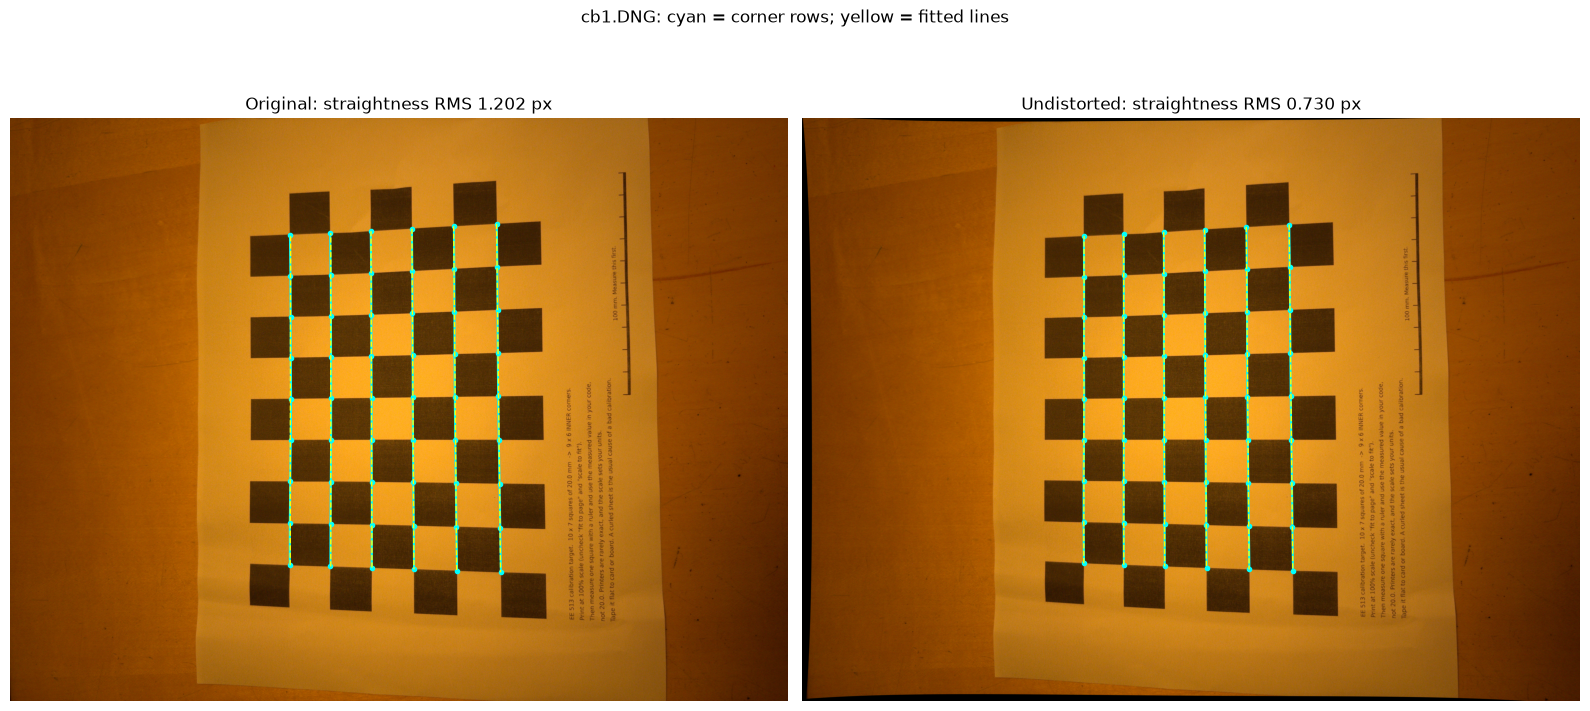

In [27]:
importlib.reload(utils) #reload utils file 
if not measurement1ValidPaths:
    raise ValueError("No detected checkerboard is available for comparison")
imagePath = measurement1ValidPaths[0]
originalPoints = imgpoints[0]

with rawpy.imread(str(imagePath)) as raw:
    rgb = raw.postprocess(user_flip=0)

image = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
targetSize = (image.shape[1], image.shape[0])
if targetSize != imageSize:
    raise ValueError(f"Target size {targetSize} differs from calibration size {imageSize}")

newCameraMatrix = mtx.copy()  # Preserve pixel scale for the before/after metric.
R = np.eye(3, dtype=np.float32)

map_x, map_y = cv2.initUndistortRectifyMap(
    cameraMatrix=mtx,
    distCoeffs=dist,
    R=R,
    newCameraMatrix=newCameraMatrix,
    size=imageSize,
    # m1type=cv2.CV_32FC1 # Map type (or cv2.CV_16SC2 for faster fixed-point)
    m1type=cv2.CV_16SC2
)

rectified_img = cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR)

correctedPoints = cv2.undistortPoints(
    originalPoints, mtx, dist, P=newCameraMatrix,
)
originalStraightness = utils.measure_checkerboard_straightness(originalPoints, boardSize)
correctedStraightness = utils.measure_checkerboard_straightness(correctedPoints, boardSize)
pointShiftsPx = np.linalg.norm(
    correctedPoints.reshape(-1, 2) - originalPoints.reshape(-1, 2), axis=1,
)
comparisonFigure, comparisonAxes = plt.subplots(1, 2, figsize=(16, 8))
for ax, pixels, title, metrics in zip(
    comparisonAxes, (image, rectified_img), ("Original", "Undistorted"),
    (originalStraightness, correctedStraightness),
):
    ax.imshow(cv2.cvtColor(pixels, cv2.COLOR_BGR2RGB))
    for line in metrics["lines"]:
        if line["direction"] == "row":
            points, segment = line["points"], line["segment"]
            ax.plot(points[:, 0], points[:, 1], "o-", color="cyan", markersize=3)
            ax.plot(segment[:, 0], segment[:, 1], "--", color="yellow", linewidth=1)
    ax.set_title(f"{title}: straightness RMS {metrics['rmsPx']:.3f} px")
    ax.axis("off")
comparisonFigure.suptitle(f"{imagePath.name}: cyan = corner rows; yellow = fitted lines")
comparisonFigure.tight_layout()
comparisonFigure.savefig("images/d2.png", dpi=160)
print("Perpendicular residuals to fitted checkerboard rows AND columns:")
for label, metrics in (("Original", originalStraightness), ("Undistorted", correctedStraightness)):
    print(f"{label}: RMS {metrics['rmsPx']:.3f} px; max {metrics['maxPx']:.3f} px")
if originalStraightness["rmsPx"] > 1e-9:
    reductionPercent = 100 * (1 - correctedStraightness["rmsPx"] / originalStraightness["rmsPx"])
    print(f"Straightness RMS reduction: {reductionPercent:.1f}% (negative means worse)")
else:
    print("RMS reduction undefined: original points are already straight")
print(f"Corner displacement: mean {pointShiftsPx.mean():.3f} px; max {pointShiftsPx.max():.3f} px")
print("Same pixel scale; transformed detected corners, not redetected corners.")
print("In-sample geometry check, not independent validation or reprojection error.")
plt.show()


In [28]:
print(dist)
print(mtx)

[[ 0.10608542 -0.19231271  0.00346061 -0.00681372  0.        ]]
[[  3.12273108e+03   0.00000000e+00   1.99069823e+03]
 [  0.00000000e+00   3.12787831e+03   1.52469705e+03]
 [  0.00000000e+00   0.00000000e+00   1.00000000e+00]]


## Measurement 2: MTF

In [2]:
importlib.reload(utils) #reload utils file 

## Import Images
measurement2ImageFolder = Path("images")
measurement2ImagePaths = sorted(
    measurement2ImageFolder.glob("edge*.DNG"),
    key=lambda imagePath: int(imagePath.stem[4:]),
)

greenPlanes = {}
for index, path in enumerate(measurement2ImagePaths):
    
    print(f"Processing image {index}: {path}")
    with rawpy.imread(str(path)) as raw:
        channel = int(raw.raw_colors_visible[0, 1])
        assert raw.color_desc[channel:channel + 1] == b'G'
        blackLevel = float(raw.black_level_per_channel[channel])
        greenLayer = raw.raw_image_visible[0::2, 1::2].astype(np.float32)
        greenLayer -= blackLevel
    greenPlanes[path.name] = greenLayer
    print(f'{path.name}: black level = {blackLevel}, shape = {greenLayer.shape}')

Processing image 0: images\edge1.DNG
edge1.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 1: images\edge2.DNG
edge2.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 2: images\edge3.DNG
edge3.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 3: images\edge4.DNG
edge4.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 4: images\edge5.DNG
edge5.DNG: black level = 528.0, shape = (1512, 2016)


In [11]:
importlib.reload(utils) #reload utils file 

p = 2 ##um pixel from Apple
nF = np.divide(1,4*p) # Nyquist frequency in 1/um

for imageName, greenPlane in greenPlanes.items():
    displayMin, displayMax = np.percentile(greenPlane, (1, 99))
    print(f"{imageName}: displayMin = {displayMin}, displayMax = {displayMax}")
squareSelections, mtf50, measuredModulationAtNyquist = utils.calculate_mtf50_from_mtf( greenPlanes, p, nF)
centerMTF50 = mtf50.copy()

# convert to cycles/pixel 
mtf50_cy_per_px = {imageName: value * p for imageName, value in mtf50.items()}
print(mtf50_cy_per_px)
print(f"\nMean: {np.mean(list(mtf50_cy_per_px.values()))}")
print(f"Standard deviation: {np.std(list(mtf50_cy_per_px.values()))}")

edge1.DNG: displayMin = 62.0, displayMax = 891.0
edge2.DNG: displayMin = 62.0, displayMax = 891.0
edge3.DNG: displayMin = 62.0, displayMax = 890.0
edge4.DNG: displayMin = 63.0, displayMax = 890.0
edge5.DNG: displayMin = 63.0, displayMax = 886.0
{'edge1.DNG': 0.23975839153271819, 'edge2.DNG': 0.22501543136703508, 'edge3.DNG': 0.21967678822079517, 'edge4.DNG': 0.22140260814321822, 'edge5.DNG': 0.23547401590422151}

Mean: 0.22826544703359763
Standard deviation: 0.00794326706202591


In [12]:
# Compare each corner across the same five captures (cycles/micrometer).
importlib.reload(utils)
options = ["top-left", "top-right", "bottom-left", "bottom-right"]

edgeImageNames = [f"edge{index}.DNG" for index in range(1, 6)]
edgeGreenPlanes = {imageName: greenPlanes[imageName] for imageName in edgeImageNames}

edgeSquareMTF50 = {}
edgeSquareSelections = {}
edgeSquareMeasuredModulationAtNyquist = {}

for option in options:
    squareSelections, mtf50, measuredModulationAtNyquist = utils.calculate_mtf50_from_mtf(
        edgeGreenPlanes, p, nF, target=option
    )
    unresolvedImages = [imageName for imageName, value in mtf50.items() if not np.isfinite(value)]
    if unresolvedImages:
        raise ValueError(f"{option}: unresolved MTF50 for {unresolvedImages}; inspect the edge ROIs")
    edgeSquareMTF50[option] = mtf50
    edgeSquareSelections[option] = squareSelections
    edgeSquareMeasuredModulationAtNyquist[option] = measuredModulationAtNyquist

edgeSquareAverageMTF50 = {
    option: float(np.mean([edgeSquareMTF50[option][imageName] for imageName in edgeImageNames]))
    for option in options
}
worstCorner = min(edgeSquareAverageMTF50, key=lambda option: edgeSquareAverageMTF50[option])
worstCornerAverageMTF50 = edgeSquareAverageMTF50[worstCorner]

# Use original sensor pitch, not the subsampled green-plane spacing (2 * p).
edgeSquareMTF50CyclesPerPixel = {
    option: {imageName: value * p for imageName, value in measurements.items()}
    for option, measurements in edgeSquareMTF50.items()
}
edgeSquareAverageCyclesPerPixel = {
    option: value * p for option, value in edgeSquareAverageMTF50.items()
}
worstCornerAverageCyclesPerPixel = worstCornerAverageMTF50 * p

print("\nMTF50 (cycles/original sensor pixel)")
print(f"{'Image':<12}" + "".join(f"{option:>15}" for option in options))
for imageName in edgeImageNames:
    print(f"{imageName:<12}" + "".join(
        f"{edgeSquareMTF50CyclesPerPixel[option][imageName]:>15.6f}" for option in options
    ))
print(f"{'Average':<12}" + "".join(
    f"{edgeSquareAverageCyclesPerPixel[option]:>15.6f}" for option in options
))
print(f"\nWorst corner average: {worstCorner} = {worstCornerAverageCyclesPerPixel:.6f} cycles/original sensor pixel")


MTF50 (cycles/original sensor pixel)
Image              top-left      top-right    bottom-left   bottom-right
edge1.DNG          0.200008       0.179266       0.187042       0.211291
edge2.DNG          0.198646       0.162487       0.200312       0.209209
edge3.DNG          0.198878       0.163045       0.193842       0.185150
edge4.DNG          0.178643       0.176874       0.204352       0.210482
edge5.DNG          0.178147       0.169428       0.225861       0.182133
Average            0.190864       0.170220       0.202282       0.199653

Worst corner average: top-right = 0.170220 cycles/original sensor pixel


In [13]:
## Update JSON with calculated MTF50 values
importlib.reload(utils)

centerCyclesPerPixel = np.array(list(centerMTF50.values())) * p
cornerCyclesPerPixel = np.array([
    value for measurements in edgeSquareMTF50CyclesPerPixel.values()
    for value in measurements.values()
])
worstCornerCyclesPerPixel = list(edgeSquareMTF50CyclesPerPixel[worstCorner].values())
utils.update_json_values(Path("results.json"), {
    "mtf50_center_cy_per_px": [float(np.mean(centerCyclesPerPixel)), float(np.std(centerCyclesPerPixel))],
    "mtf50_corner_mean_cy_per_px": [float(np.mean(cornerCyclesPerPixel)), float(np.std(cornerCyclesPerPixel))],
    "mtf50_corner_worst_cy_per_px": [worstCornerAverageCyclesPerPixel, float(np.std(worstCornerCyclesPerPixel))]
})

## Measurement 3: Noise Models

In [2]:
importlib.reload(utils) #reload utils file 

## Import Images
measurement3Folder = Path("../../exercises/03_assignment/images")
measurement3FlatFieldImagePaths = sorted(
    (imagePath for imagePath in measurement3Folder.glob("*.DNG") if ("dark" not in imagePath.stem.lower()) and ('cb' not in imagePath.stem.lower())),
    key=lambda imagePath: (int(imagePath.stem[:-1]), imagePath.stem[-1].lower()),
)

measurement3DarkImagePaths = sorted(
    (imagePath for imagePath in measurement3Folder.glob("*.DNG") if "dark" in imagePath.stem.lower()),
    key=lambda imagePath: imagePath.stem.lower(),
)

In [3]:
# Difference-of-pairs photon-transfer measurement on the central green patch.
measurement3ImagePairs = list(zip(
    measurement3FlatFieldImagePaths[::2],
    measurement3FlatFieldImagePaths[1::2],
))
if len(measurement3FlatFieldImagePaths) % 2:
    raise ValueError("Every flat field must have a matching second exposure")
if not measurement3ImagePairs:
    raise FileNotFoundError(
        f"No paired flat fields found in {measurement3Folder.resolve()}"
    )

with rawpy.imread(str(measurement3FlatFieldImagePaths[0])) as raw:
    blackLevelDN = float(np.mean(raw.black_level_per_channel))
    saturationDN = float(raw.white_level - blackLevelDN)

meanSignalDN, pairVarianceDN2 = utils.measure_flat_field_pairs(
    measurement3ImagePairs,
    blackLevelDN,
    roiSize=128,
)

In [4]:
# Restrict the calibration fit to the linear central-patch range.
saturationLimitDN = 0.7 * saturationDN
fitMask = (
    (meanSignalDN >= 50)
    & (meanSignalDN <= 700)
    & (meanSignalDN < saturationLimitDN)
)
if np.count_nonzero(fitMask) < 3:
    raise ValueError("At least three flat pairs are required in the linear fit range")

(fitSlopeDNPerElectron, fitInterceptDN2), fitCovariance = np.polyfit(
    meanSignalDN[fitMask], pairVarianceDN2[fitMask], 1, cov=True
)
fitSlopeStdDNPerElectron = float(np.sqrt(fitCovariance[0, 0]))
fitInterceptStdDN2 = float(np.sqrt(fitCovariance[1, 1]))
conversionGainDNPerElectron = float(fitSlopeDNPerElectron)
if not np.isfinite(conversionGainDNPerElectron) or conversionGainDNPerElectron <= 0:
    raise ValueError("The photon-transfer fit must give a positive finite gain")
conversionGainStdDNPerElectron = fitSlopeStdDNPerElectron
conversionGainElectronPerDN = 1 / conversionGainDNPerElectron
conversionGainStdElectronPerDN = (
    fitSlopeStdDNPerElectron / conversionGainDNPerElectron ** 2
)
print(f"Flat pairs: {len(measurement3ImagePairs)}; central patch: 128 x 128")
print(
    f"Fit range: {meanSignalDN[fitMask].min():.1f}-"
    f"{meanSignalDN[fitMask].max():.1f} DN; "
    f"{np.count_nonzero(fitMask)} flat levels"
)
print(
    f"Conversion gain: {conversionGainDNPerElectron:.4f} ± "
    f"{conversionGainStdDNPerElectron:.4f} DN/electron "
    "(1-sigma fit covariance SE)"
)
print(
    f"Reciprocal gain: {conversionGainElectronPerDN:.3f} ± "
    f"{conversionGainStdElectronPerDN:.3f} electrons/DN (fit covariance SE)"
)
print(
    f"Variance intercept: {fitInterceptDN2:.4f} ± "
    f"{fitInterceptStdDN2:.4f} DN^2 (fit covariance SE)"
)


Flat pairs: 11; central patch: 128 x 128
Fit range: 105.4-616.1 DN; 5 flat levels
Conversion gain: 0.2620 ± 0.0061 DN/electron (1-sigma fit covariance SE)
Reciprocal gain: 3.817 ± 0.089 electrons/DN (fit covariance SE)
Variance intercept: 0.0678 ± 2.3179 DN^2 (fit covariance SE)


For two independent dark frames, `std(A - B, ddof=1) / sqrt(2)` estimates the single-frame temporal noise in DN. With conversion gain `K` in DN/electron, this equals `K * read_noise_e`; divide by `K` once to obtain electrons RMS. We pool the ten pair variances from the five dark frames, then take the square root. The existing `utils.measure_flat_field_pairs` helper implements exactly `variance(A - B) / 2` on the same central green patch.

Gain and intercept standard errors come from `sqrt(diag(covariance))` with `np.polyfit(..., cov=True)`, not the simulation demo's percentage errors. Propagating the gain error gives `read_noise_e * sigma_K / K`, conditional on the measured dark noise. This is **gain-only** uncertainty, not the total read-noise uncertainty: the dark pairs share frames and are not ten independent estimates. Their unequal exposure times can also contribute dark-current shot noise, so the dark-frame noise is an approximate read-noise estimate.

In [5]:
# Measure dark current and temporal read noise in a central 128 x 128 patch.
darkExposureSeconds = []
darkSignalElectrons = []
darkFramePatchesDN = []
for imagePath in measurement3DarkImagePaths:
    with rawpy.imread(str(imagePath)) as raw:
        greenChannel = int(raw.raw_pattern[0, 1])
        greenPlane = raw.raw_image_visible[0::2, 1::2].astype(float)
        greenBlackLevelDN = float(raw.black_level_per_channel[greenChannel])
        top = (greenPlane.shape[0] - 128) // 2
        left = (greenPlane.shape[1] - 128) // 2
        centralPatch = greenPlane[top:top + 128, left:left + 128]
        darkFramePatchesDN.append(centralPatch.copy())
        darkSignalDN = float(centralPatch.mean() - greenBlackLevelDN)

    with tifffile.TiffFile(imagePath) as dng:
        exposureNumerator, exposureDenominator = (
            dng.pages[0].tags["ExifTag"].value["ExposureTime"]
        )
    exposureTimeSeconds = exposureNumerator / exposureDenominator
    darkExposureSeconds.append(exposureTimeSeconds)
    darkSignalElectrons.append(darkSignalDN * conversionGainElectronPerDN)
    print(
        f"{imagePath.name}: {exposureTimeSeconds:.4f} s, "
        f"{darkSignalDN:.3f} DN above black"
    )

if len(darkFramePatchesDN) < 2:
    raise ValueError("At least two dark frames are required for a difference estimate")
darkImagePairs = [
    (firstPatch, secondPatch)
    for firstIndex, firstPatch in enumerate(darkFramePatchesDN)
    for secondPatch in darkFramePatchesDN[firstIndex + 1:]
]
_, darkPairVariancesDN2 = utils.measure_flat_field_pairs(
    darkImagePairs,
    blackLevel=0,
    roiSize=128,
)

darkReadNoiseDN = float(np.sqrt(np.mean(darkPairVariancesDN2)))
darkReadNoiseElectrons = darkReadNoiseDN / conversionGainDNPerElectron
darkReadNoiseGainStdElectrons = (
    darkReadNoiseElectrons * conversionGainStdDNPerElectron
    / conversionGainDNPerElectron
)
photonReadNoiseCrossoverElectrons = darkReadNoiseElectrons ** 2
photonReadNoiseCrossoverDN = (
    photonReadNoiseCrossoverElectrons * conversionGainDNPerElectron
)
print(
    f"Dark-frame difference read noise: {darkReadNoiseDN:.3f} DN RMS "
    f"({darkReadNoiseElectrons:.3f} ± {darkReadNoiseGainStdElectrons:.3f} "
    "electrons RMS; 1-sigma gain-fit uncertainty only)"
)
print(
    f"Photon/read-noise crossover: {photonReadNoiseCrossoverElectrons:.1f} "
    f"electrons ({photonReadNoiseCrossoverDN:.1f} DN)"
)


dark1.DNG: 0.5000 s, 0.028 DN above black
dark2.DNG: 1.0000 s, 0.224 DN above black
dark3.DNG: 0.1000 s, -0.501 DN above black
dark4.DNG: 0.0333 s, -0.527 DN above black
dark5.DNG: 0.0217 s, -0.372 DN above black
Dark-frame difference read noise: 1.798 DN RMS (6.863 ± 0.160 electrons RMS; 1-sigma gain-fit uncertainty only)
Photon/read-noise crossover: 47.1 electrons (12.3 DN)


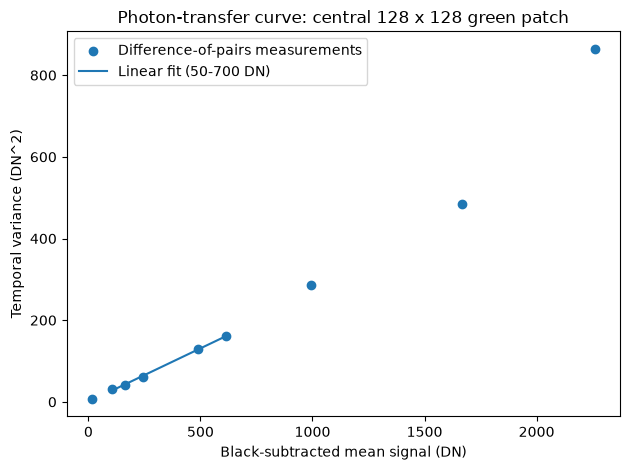

Single-frame spatial-variance comparison over the same signal range:
  slope: 0.2870 DN/electron
  intercept: -2.2888 DN^2
  spatial-variance intercept is not used as a read-noise estimate


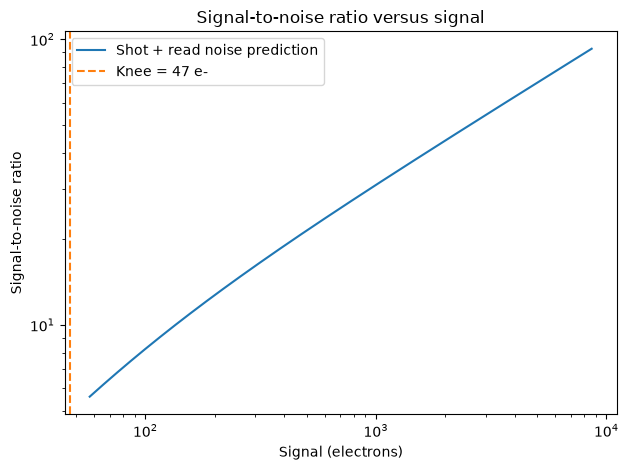

SNR: 105.4 DN (402.3 e-): 18.978
SNR: 161.2 DN (615.3 e-): 23.907
SNR: 243.3 DN (928.5 e-): 29.726
SNR: 491.2 DN (1874.7 e-): 42.764
SNR: 616.1 DN (2351.7 e-): 48.016
SNR: 994.5 DN (3795.8 e-): 61.231
SNR: 1668.9 DN (6370.1 e-): 79.519
SNR: 2260.0 DN (8626.0 e-): 92.624
SNR: 15.0 DN (57.3 e-): 5.608
DNG NoiseProfile coefficients: (9.63074e-05, 9.76561e-07)
NoiseProfile conversion gain: 2.911 electrons/DN
NoiseProfile read noise: 10.26 electrons RMS
NoiseProfile crossover: 105.29 electrons


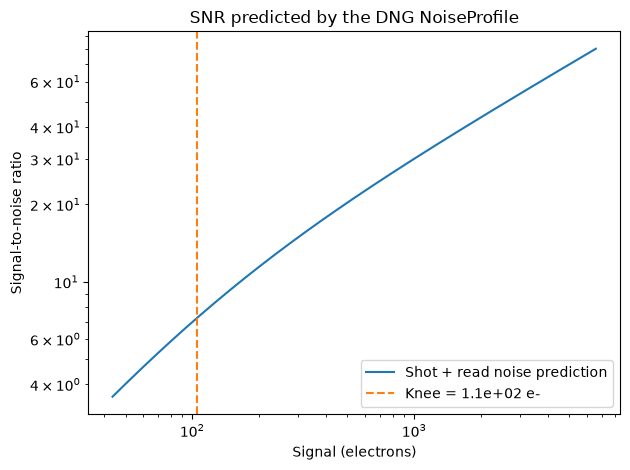

In [6]:

fig, ax = plt.subplots()
ax.scatter(
    meanSignalDN[meanSignalDN < saturationLimitDN],
    pairVarianceDN2[meanSignalDN < saturationLimitDN],
    label="Difference-of-pairs measurements",
)
fitSignalDN = np.linspace(meanSignalDN[fitMask].min(), meanSignalDN[fitMask].max(), 100)
ax.plot(
    fitSignalDN,
    fitSlopeDNPerElectron * fitSignalDN + fitInterceptDN2,
    label="Linear fit (50-700 DN)",
)
ax.set_xlabel("Black-subtracted mean signal (DN)")
ax.set_ylabel("Temporal variance (DN^2)")
ax.set_title("Photon-transfer curve: central 128 x 128 green patch")
ax.legend()
fig.tight_layout()
fig.savefig(Path("images") / "d3_photon_transfer.png", dpi=160)
plt.show()

# A single-frame spatial variance includes PRNU, fixed pattern, and shading.
singleFramePaths = measurement3FlatFieldImagePaths[::2]
singleMeanDN, singleVarianceDN2 = utils.measure_flat_field_single(
    singleFramePaths,
    blackLevelDN,
    roiSize=128,
)
singleFitMask = (singleMeanDN >= 50) & (singleMeanDN <= 700)
singleSlopeDNPerElectron, singleInterceptDN2 = np.polyfit(
    singleMeanDN[singleFitMask], singleVarianceDN2[singleFitMask], 1
)
print("Single-frame spatial-variance comparison over the same signal range:")
print(f"  slope: {singleSlopeDNPerElectron:.4f} DN/electron")
print(f"  intercept: {singleInterceptDN2:.4f} DN^2")
print("  spatial-variance intercept is not used as a read-noise estimate")

# Plot predicted SNR from the fitted shot-plus-read-noise model.
validSignal = (meanSignalDN > 0) & (meanSignalDN < saturationLimitDN)
measuredSignalElectrons = meanSignalDN[validSignal] * conversionGainElectronPerDN
measuredSNR = utils.calculate_signal_to_noise(
    measuredSignalElectrons,
    darkReadNoiseElectrons,
)
snrAxes = utils.plot_snr_vs_signal(
    meanSignalDN[validSignal],
    conversionGainElectronPerDN,
    darkReadNoiseElectrons,
)
snrAxes.figure.tight_layout()
snrAxes.figure.savefig(Path("images") / "d3_snr.png", dpi=160)
plt.show()
for signalDN, signalElectrons, snrValue in zip(
    meanSignalDN[validSignal], measuredSignalElectrons, measuredSNR
):
    print(f"SNR: {signalDN:.1f} DN ({signalElectrons:.1f} e-): {snrValue:.3f}")

# Compare the capture fit with the DNG's vendor NoiseProfile coefficients.
noiseProfileStatus = utils.get_noise_profile_status(measurement3FlatFieldImagePaths[0])
if not noiseProfileStatus["present"]:
    raise ValueError("NoiseProfile tag is missing from the selected flat-field DNG")
noiseProfileSlope, noiseProfileOffset = noiseProfileStatus["values"]
noiseProfileSlopeDNPerElectron = noiseProfileSlope * saturationDN
noiseProfileInterceptDN2 = noiseProfileOffset * saturationDN ** 2
noiseProfileGainElectronPerDN = 1 / noiseProfileSlopeDNPerElectron
noiseProfileReadNoiseElectrons = (
    np.sqrt(noiseProfileInterceptDN2) / noiseProfileSlopeDNPerElectron
)
noiseProfileCrossoverElectrons = noiseProfileReadNoiseElectrons ** 2
print(f"DNG NoiseProfile coefficients: {noiseProfileStatus['values']}")
print(f"NoiseProfile conversion gain: {noiseProfileGainElectronPerDN:.3f} electrons/DN")
print(f"NoiseProfile read noise: {noiseProfileReadNoiseElectrons:.2f} electrons RMS")
print(f"NoiseProfile crossover: {noiseProfileCrossoverElectrons:.2f} electrons")
noiseProfileAxes = utils.plot_snr_vs_signal(
    meanSignalDN[validSignal],
    noiseProfileGainElectronPerDN,
    noiseProfileReadNoiseElectrons,
)
noiseProfileAxes.set_title("SNR predicted by the DNG NoiseProfile")
noiseProfileAxes.figure.tight_layout()
noiseProfileAxes.figure.savefig(Path("images") / "d3_noise_profile_snr.png", dpi=160)
plt.show()


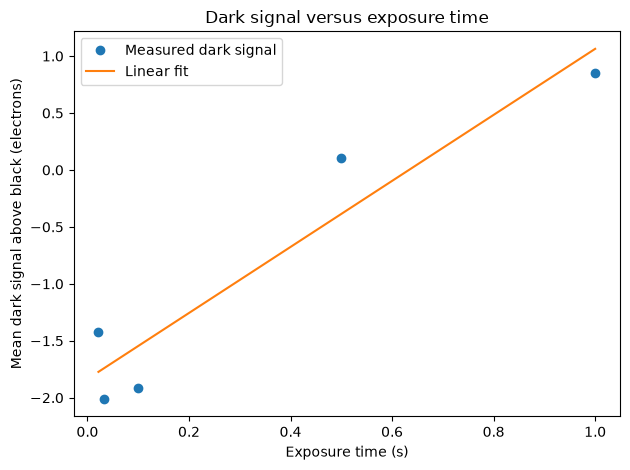

Dark-current fit: 2.899 ± 0.537 electrons/pixel/second (fit covariance SE)
Caution: these dark signals are close to black-level variation; the slope is only a weak estimate. The dark frames have unequal exposure times, so their pairwise differences can also include a small dark-current shot-noise contribution.


In [7]:
darkCurrentResults = utils.plot_dark_current(
    darkExposureSeconds,
    darkSignalElectrons,
)
darkCurrentAxes = darkCurrentResults["ax"]
darkCurrentAxes.figure.tight_layout()
darkCurrentAxes.figure.savefig(Path("images") / "d3_dark_current.png", dpi=160)
plt.show()
(darkCurrentElectronsPerSecond, darkCurrentInterceptElectrons), darkCurrentCovariance = (
    np.polyfit(darkExposureSeconds, darkSignalElectrons, 1, cov=True)
)
darkCurrentStdElectronsPerSecond = float(np.sqrt(darkCurrentCovariance[0, 0]))
darkCurrentInterceptStdElectrons = float(np.sqrt(darkCurrentCovariance[1, 1]))
print(
    f"Dark-current fit: {darkCurrentElectronsPerSecond:.3f} ± "
    f"{darkCurrentStdElectronsPerSecond:.3f} electrons/pixel/second "
    f"(fit covariance SE)"
)
print(
    "Caution: these dark signals are close to black-level variation; "
    "the slope is only a weak estimate. The dark frames have unequal "
    "exposure times, so their pairwise differences can also include a "
    "small dark-current shot-noise contribution."
)


## Measurement 3 results

Using paired flat captures and the central 128 x 128 green patch, the photon-transfer fit uses five flat levels from 50 to 700 DN. The conversion gain is **0.2620 ± 0.0061 DN/electron**, with a 1-sigma standard error from `np.polyfit(..., cov=True)`. The reciprocal is **3.817 ± 0.089 electrons/DN**, using propagated gain-fit covariance. The variance intercept is **0.0678 ± 2.3179 DN^2** and is not used to infer read noise.

Read noise is measured from all ten pixel-wise differences between the five lens-capped dark frames. The pooled difference standard deviation is **2.543 DN**; dividing by `sqrt(2)` gives the single-frame temporal noise of **1.798 DN RMS**. Dividing by the fitted gain gives **6.86 ± 0.16 electrons RMS**. This ± is the propagated **gain-fit uncertainty only**, not a total read-noise standard error and not a demo percentage. The ten pairs share frames, and the unequal exposure times may contribute dark-current shot noise. Their low signals (within about 0.5 DN of black) also make dark-current estimation weak.

The predicted SNR curve is `signal_e / sqrt(signal_e + read_noise_e^2)`. Photon-shot-noise and read-noise variances meet at **47.1 electrons**, equivalent to about **12.3 DN**. The DNG `NoiseProfile` `(9.63074e-05, 9.76561e-07)` predicts 2.911 electrons/DN and 10.26 electrons RMS read noise (105.29-electron crossover), so its read-noise estimate is higher than the dark-frame estimate and is reported as a comparison rather than averaged with it.

Flat-field noise is calculated as `sample_variance(A - B) / 2`: fixed shading and pixel-response structure shared by paired captures cancel, leaving temporal noise. A single-frame spatial variance also contains those fixed patterns and lens shading, so its fitted intercept is not a valid read-noise estimate. Dark current from the five lens-capped exposures is **2.90 ± 0.54 electrons/pixel/second** (fit covariance standard error); because the means lie near black-level variation, treat this slope cautiously. The figures are saved in `images/d3_*.png` when the analysis cells run.


In [10]:
measurement3ReferencePath = measurement3FlatFieldImagePaths[0]
noiseMeasurementISO = int(utils.lens_id(measurement3ReferencePath)["iso"])
with rawpy.imread(str(measurement3ReferencePath)) as raw:
    whiteLevelDN = int(raw.white_level)

utils.update_json_values(Path("results.json"), {
    "conversion_gain_dn_per_e": [
        float(conversionGainDNPerElectron),
        float(conversionGainStdDNPerElectron),
    ],
    "read_noise_e": [
        float(darkReadNoiseElectrons),
        float(darkReadNoiseGainStdElectrons),  # Gain-fit uncertainty only.
    ],
    "dark_current_e_per_s": [
        float(darkCurrentElectronsPerSecond),
        float(darkCurrentStdElectronsPerSecond),
    ],
    "iso_of_noise_measurement": noiseMeasurementISO,
    "black_level_dn": [float(blackLevelDN), None],  # Metadata; uncertainty not estimated.
    "white_level_dn": whiteLevelDN,
    "vendor_noiseprofile_present": bool(noiseProfileStatus["present"]),
})


## Measurement 4: Dynamic Range

Dynamic range is reported as black-subtracted RAW saturation divided by the temporal read-noise floor. The low-end criterion is one RMS read-noise level (SNR = 1); other noise-floor thresholds or conventions produce different stop counts.

In [8]:
if not np.isfinite(darkReadNoiseDN) or darkReadNoiseDN <= 0:
    raise ValueError("A positive finite read-noise floor is required")
dynamicRangeStops = np.log2(saturationDN / darkReadNoiseDN)
print(
    f"Dynamic range: log2({saturationDN:.1f} DN / "
    f"{darkReadNoiseDN:.3f} DN) = {dynamicRangeStops:.2f} stops"
)

Dynamic range: log2(3567.0 DN / 1.798 DN) = 10.95 stops


In [9]:
utils.update_json_values(Path("results.json"), {
    "dynamic_range_stops": [float(np.mean(dynamicRangeStops)), float(np.std(dynamicRangeStops))],
})

## Measurement 5: Color Accuracy

Use `IMG_0297.DNG` as the per-channel flat field for chart captures `IMG_0294.DNG` through `IMG_0296.DNG`, then average the three linear-camera-RGB patch measurements. White-balance gains are derived from chart white patch 19. Before matrix correction, the white-balanced linear camera RGB is treated as linear sRGB; the least-squares 3 x 3 matrix maps the same white-balanced camera RGB to XYZ. Both are compared with CIEDE2000 under the chart reference illuminant.

Reference values are from `ColorChecker24 - After November 2014`, matching the 24-patch chart and the reference set used in Assignment 4. Its D50 illuminant is used for both XYZ-to-Lab conversions; using another chart revision or illuminant would change the reported errors.

Color matrix (XYZ = M @ (white-balanced camera RGB)):
[[  6.20376152e-01   4.00648291e-01  -5.55923180e-02]
 [  1.83148654e-01   1.12168450e+00  -2.92099108e-01]
 [ -6.53013063e-04  -2.88700608e-01   1.09053669e+00]]
Fit patches: 24/24; Delta E is CIEDE2000
Patch | Before | After
 1 dark skin | 6.16 | 2.60
 2 light skin | 6.34 | 2.75
 3 blue sky | 4.72 | 1.97
 4 foliage | 9.34 | 2.53
 5 blue flower | 6.94 | 1.33
 6 bluish green | 10.40 | 1.14
 7 orange | 8.23 | 3.58
 8 purplish blue | 8.28 | 2.34
 9 moderate red | 9.30 | 2.80
10 purple | 9.61 | 1.55
11 yellow green | 12.91 | 1.00
12 orange yellow | 12.27 | 1.93
13 blue | 7.29 | 3.30
14 green | 11.87 | 3.54
15 red | 8.71 | 2.89
16 yellow | 13.50 | 1.17
17 magenta | 11.66 | 0.58
18 cyan | 11.06 | 3.39
19 white 9.5 (.05 D) | 3.09 | 1.16
20 neutral 8 (.23 D) | 2.06 | 1.24
21 neutral 6.5 (.44 D) | 2.36 | 1.89
22 neutral 5 (.70 D) | 2.44 | 2.10
23 neutral 3.5 (1.05 D) | 1.74 | 1.48
24 black 2 (1.5 D) | 2.83 | 3.12
Before: mean ΔE00 7.63; acr

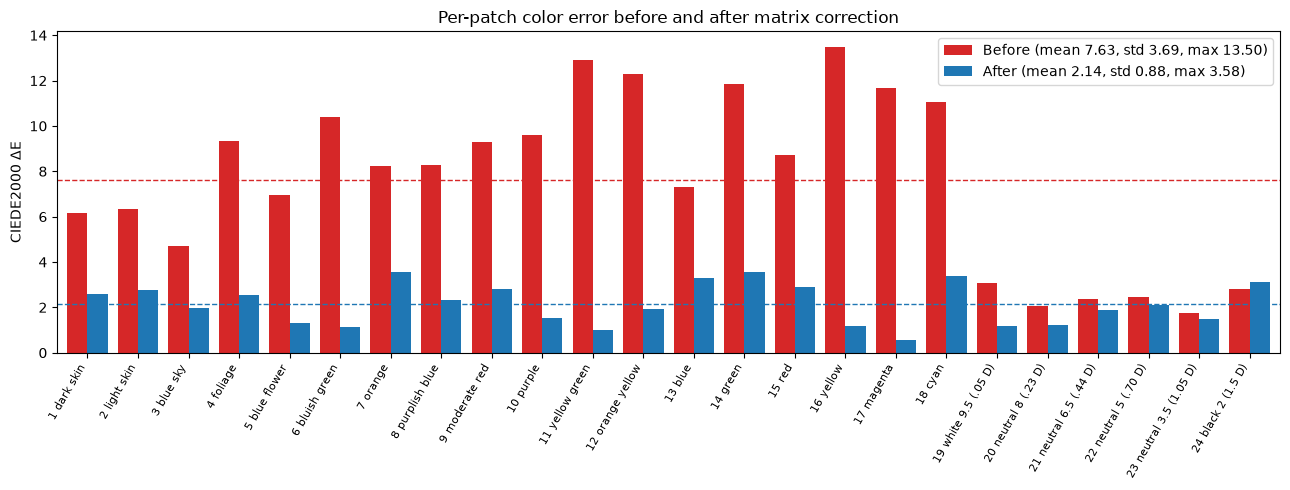

In [12]:
importlib.reload(utils)

measurement5ImageFolder = Path("../../exercises/04_assignment/images")
measurement5ChartPaths = [
    measurement5ImageFolder / f"IMG_{imageNumber}.DNG"
    for imageNumber in ("0294", "0295", "0296")
]
measurement5FlatFieldPath = measurement5ImageFolder / "IMG_0297.DNG"
for imagePath in [*measurement5ChartPaths, measurement5FlatFieldPath]:
    if not imagePath.is_file():
        raise FileNotFoundError(f"Missing color-chart image: {imagePath.resolve()}")

with rawpy.imread(str(measurement5FlatFieldPath)) as raw:
    measurement5SaturationValue = float(raw.white_level)
measurement5FlatFieldRgb = utils.raw_to_linear_rgb(
    measurement5FlatFieldPath,
    measurement5SaturationValue,
)["stack"]

measurement5PatchMeans = []
for imagePath in measurement5ChartPaths:
    chartRgb = utils.raw_to_linear_rgb(
        imagePath,
        measurement5SaturationValue,
    )["stack"]
    correctedChartRgb = utils.flat_field_correct(
        chartRgb,
        measurement5FlatFieldRgb,
)["corrected"]
    patchResults = utils.extract_colorchecker_means(correctedChartRgb)
    measurement5PatchMeans.append(patchResults["meanRgb"])

measurement5CameraRgb = np.mean(measurement5PatchMeans, axis=0)
measurement5ReferenceXYZ = np.asarray(t_XYZ)
measurement5ReferenceIlluminant = np.asarray(cc24_data.illuminant)
measurement5PatchNames = list(cc24_data.data.keys())
measurement5Baseline = utils.srgb_baseline_color_error(
    measurement5CameraRgb,
    measurement5ReferenceXYZ,
    measurement5ReferenceIlluminant,
    whiteIndex=18,
)
measurement5Fit = utils.fit_color_correction_matrix(
    measurement5CameraRgb,
    measurement5ReferenceXYZ,
    measurement5ReferenceIlluminant,
    colorGain=measurement5Baseline["whiteBalanceGains"],
)
measurement5Axes, measurement5Summary = utils.plot_delta_e_before_after(
    measurement5Baseline["deltaE"],
    measurement5Fit["deltaE"],
    measurement5PatchNames,
    statsMask=measurement5Fit["fitMask"],
)
measurement5Axes.figure.savefig(
    Path("images") / "d5_color_accuracy.png",
    dpi=200,
    bbox_inches="tight",
)
print("Color matrix (XYZ = M @ (white-balanced camera RGB)):")
print(measurement5Fit["colorMatrix"])
print(
    f"Fit patches: {measurement5Fit['fitMask'].sum()}/24; "
    "Delta E is CIEDE2000"
)
print("Patch | Before | After")
for patchNumber, (patchName, before, after) in enumerate(
    zip(
        measurement5PatchNames,
        measurement5Baseline["deltaE"],
        measurement5Fit["deltaE"],
    ),
    start=1,
):
    print(f"{patchNumber:2d} {patchName} | {before:.2f} | {after:.2f}")
for condition in ("before", "after"):
    stats = measurement5Summary[condition]
    worstPatchNumber, worstPatchName, worstDeltaE = stats["worstPatches"][0]
    print(
        f"{condition.capitalize()}: mean ΔE00 {stats['meanDeltaE']:.2f}; "
        f"across-patch std {stats['stdDeltaE']:.2f}; "
        f"worst patch {worstPatchNumber} ({worstPatchName}), "
        f"ΔE00 {worstDeltaE:.2f}"
    )
plt.show()

In [13]:
utils.update_json_values(Path("results.json"), {
    "delta_e_mean_before_ccm": [
        measurement5Summary["before"]["meanDeltaE"],
        measurement5Summary["before"]["stdDeltaE"],
    ],
    "delta_e_mean_after_ccm": [
        measurement5Summary["after"]["meanDeltaE"],
        measurement5Summary["after"]["stdDeltaE"],
    ],
    "delta_e_worst_after_ccm": [measurement5Summary["after"]["maxDeltaE"], measurement5Summary["after"]["stdDeltaE"]],
})

The before/after summaries and JSON mean entries report the population standard deviation (`ddof=0`) across the same selected patches as the mean, excluding clipped patches. This is spread across chart colors, not uncertainty of the mean or capture repeatability. The worst-patch uncertainty is `null` because across-patch spread does not estimate uncertainty of a maximum.

Using the **ColorChecker24 - After November 2014** reference values under D50, the mean CIEDE2000 error over all 24 patches is **7.63 before** and **2.14 after** matrix correction. The worst patch is **16 (yellow), ΔE00 13.50 before**, and **7 (orange), ΔE00 3.58 after**. All 24 patches were included in the least-squares fit.

The fitted matrix, with `XYZ = M @ (white-balanced camera RGB)`, is:

```text
[[ 0.620376,  0.400648, -0.055592],
 [ 0.183149,  1.121685, -0.292099],
 [-0.000653, -0.288701,  1.090537]]
```

| Patch | Before ΔE00 | After ΔE00 |
|---|---:|---:|
| 1 dark skin | 6.16 | 2.60 |
| 2 light skin | 6.34 | 2.75 |
| 3 blue sky | 4.72 | 1.97 |
| 4 foliage | 9.34 | 2.53 |
| 5 blue flower | 6.94 | 1.33 |
| 6 bluish green | 10.40 | 1.14 |
| 7 orange | 8.23 | 3.58 |
| 8 purplish blue | 8.28 | 2.34 |
| 9 moderate red | 9.30 | 2.80 |
| 10 purple | 9.61 | 1.55 |
| 11 yellow green | 12.91 | 1.00 |
| 12 orange yellow | 12.27 | 1.93 |
| 13 blue | 7.29 | 3.30 |
| 14 green | 11.87 | 3.54 |
| 15 red | 8.71 | 2.89 |
| 16 yellow | 13.50 | 1.17 |
| 17 magenta | 11.66 | 0.58 |
| 18 cyan | 11.06 | 3.39 |
| 19 white 9.5 (.05 D) | 3.09 | 1.16 |
| 20 neutral 8 (.23 D) | 2.06 | 1.24 |
| 21 neutral 6.5 (.44 D) | 2.36 | 1.89 |
| 22 neutral 5 (.70 D) | 2.44 | 2.10 |
| 23 neutral 3.5 (1.05 D) | 1.74 | 1.48 |
| 24 black 2 (1.5 D) | 2.83 | 3.12 |